# Week 2 — California Single-Family Home Exploration

This notebook explores six monthly CRMLS sold files covering
January–June 2024.

The files contain 136,614 records before filtering and 68,641
Residential SingleFamilyResidence records after filtering.

The analysis reviews missing values, numeric distributions, and
relationships with ClosePrice. Sampled and percentile-restricted
charts are used for readability; these plotting selections do not
change the original dataset.

Correlations describe the selected samples and are not prediction
accuracy scores. Data cleaning and model evaluation follow in
later notebooks.

In [3]:
from pathlib import Path
import zipfile
import tempfile

zip_path = Path("/content/IDX_Analysis 2.zip")

if not zip_path.is_file():
    raise FileNotFoundError(f"ZIP not found: {zip_path}")

if not zipfile.is_zipfile(zip_path):
    raise ValueError("The ZIP is incomplete or invalid. Check the upload.")

# Use a fresh folder to avoid mixing old and new files.
data_folder = Path(tempfile.mkdtemp(
    prefix="ds_data_", dir="/content"
))

with zipfile.ZipFile(zip_path) as archive:
    archive.extractall(data_folder)

csv_files = sorted(
    p for p in data_folder.rglob("*")
    if p.is_file()
    and p.suffix.lower() == ".csv"
    and "__MACOSX" not in p.parts
    and not p.name.startswith(".")
)

sold_files = [
    p for p in csv_files
    if p.name.startswith("CRMLSSold")
]

print("Extracted to:", data_folder)
print("Total CSV files:", len(csv_files))
print("Sold CSV files:", len(sold_files))

Extracted to: /content/ds_data_ax42slf9
Total CSV files: 66
Sold CSV files: 33


In [23]:
import pandas as pd

matches = [
    p for p in sold_files
    if p.name == "CRMLSSold202402.csv"
]

if len(matches) != 1:
    raise ValueError(
        f"Expected one February 2024 sold file; found {len(matches)}."
    )

df = pd.read_csv(matches[0], low_memory=False)
print(f"February rows: {len(df):,}")
print(f"February columns: {df.shape[1]}")

February rows: 19,925
February columns: 78


In [5]:
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")

Rows: 19,925
Columns: 78


In [7]:
import pandas as pd

# Select January–June 2024 from the extracted sold files.
expected_names = [
    f"CRMLSSold2024{month:02d}.csv"
    for month in range(1, 7)
]

file_paths = []

for filename in expected_names:
    matches = [
        path for path in sold_files
        if path.name == filename
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one {filename}; found {len(matches)}."
        )

    file_paths.append(matches[0])

# Read only the headers and display each file's columns.
for path in file_paths:
    columns = pd.read_csv(path, nrows=0).columns

    print(f"\n{path.name} — {len(columns)} columns")

    for number, column in enumerate(columns, start=1):
        print(f"{number}. {column}")


CRMLSSold202401.csv — 80 columns
1. Flooring
2. ViewYN
3. WaterfrontYN
4. BasementYN
5. PoolPrivateYN
6. OriginalListPrice
7. ListingKey
8. ListAgentEmail
9. CloseDate
10. ClosePrice
11. ListAgentFirstName
12. ListAgentLastName
13. Latitude
14. Longitude
15. UnparsedAddress
16. PropertyType
17. LivingArea
18. ListPrice
19. DaysOnMarket
20. ListOfficeName
21. BuyerOfficeName
22. CoListOfficeName
23. ListAgentFullName
24. CoListAgentFirstName
25. CoListAgentLastName
26. BuyerAgentMlsId
27. BuyerAgentFirstName
28. BuyerAgentLastName
29. FireplacesTotal
30. AssociationFeeFrequency
31. AboveGradeFinishedArea
32. ListingKeyNumeric
33. MLSAreaMajor
34. TaxAnnualAmount
35. CountyOrParish
36. MlsStatus
37. ElementarySchool
38. AttachedGarageYN
39. ParkingTotal
40. BuilderName
41. PropertySubType
42. LotSizeAcres
43. SubdivisionName
44. BuyerOfficeAOR
45. YearBuilt
46. BuyerAgencyCompensationType
47. StreetNumberNumeric
48. ListingId
49. BathroomsTotalInteger
50. City
51. BuyerAgencyCompensatio

# **stacking tables with needed columns. **

In [8]:
import pandas as pd

# Columns needed for filtering, date checks, and exploration.
needed_columns = [
    "ListingKey",
    "CloseDate",
    "PropertyType",
    "PropertySubType",
    "ClosePrice",
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet"
]

monthly_data = []

# Load the six monthly files selected in the previous cell.
for path in file_paths:
    month_df = pd.read_csv(
        path,
        usecols=needed_columns,
        low_memory=False
    )

    print(f"{path.name}: {len(month_df):,} rows")
    monthly_data.append(month_df)

# Record the total before combining.
rows_before = sum(len(month) for month in monthly_data)

# Stack records, matching columns by name.
df = pd.concat(monthly_data, ignore_index=True)

assert len(df) == rows_before, "Row count changed during concatenation."

print(f"\nTotal rows before combining: {rows_before:,}")
print(f"Total rows after combining:  {len(df):,}")
print(f"Columns: {df.shape[1]}")

display(df.tail())

CRMLSSold202401.csv: 17,958 rows
CRMLSSold202402.csv: 19,925 rows
CRMLSSold202403.csv: 23,276 rows
CRMLSSold202404.csv: 24,640 rows
CRMLSSold202405.csv: 26,487 rows
CRMLSSold202406.csv: 24,328 rows

Total rows before combining: 136,614
Total rows after combining:  136,614
Columns: 9


,ListingKey,CloseDate,ClosePrice,PropertyType,LivingArea,PropertySubType,BathroomsTotalInteger,BedroomsTotal,LotSizeSquareFeet
136609,1002458546,2024-06-27,3600000.0,Land,NaN,NaN,NaN,NaN,3300977.0
136610,1001922099,2024-06-14,5000.0,Land,NaN,NaN,NaN,NaN,108900.0
136611,1001759754,2024-06-26,33000.0,Land,NaN,NaN,NaN,NaN,33541.2
136612,1001725703,2024-06-27,12000.0,Land,NaN,NaN,NaN,NaN,221720.0
136613,1001719106,2024-06-26,3495.0,ResidentialLease,1042.0,Apartment,2.0,2.0,15906.0


In [9]:
# Keep only residential single-family properties
residential_df = df[
    (df["PropertyType"] == "Residential") &
    (df["PropertySubType"] == "SingleFamilyResidence")
].copy()

print("Rows before filtering:", len(df))
print("Rows after filtering:", len(residential_df))

residential_df.head()

Rows before filtering: 136614
Rows after filtering: 68641


,ListingKey,CloseDate,ClosePrice,PropertyType,LivingArea,PropertySubType,BathroomsTotalInteger,BedroomsTotal,LotSizeSquareFeet
5,522107581,2024-01-05,815000.0,Residential,1974.0,SingleFamilyResidence,4.0,4.0,NaN
9,510919001,2024-01-05,810000.0,Residential,1974.0,SingleFamilyResidence,4.0,4.0,NaN
28,1067652762,2024-01-02,2100000.0,Residential,3736.0,SingleFamilyResidence,4.0,4.0,11219.0
29,1063453216,2024-01-22,1950000.0,Residential,2100.0,SingleFamilyResidence,0.0,3.0,74487.6
31,1061988701,2024-01-31,2340000.0,Residential,2442.0,SingleFamilyResidence,3.0,4.0,8712.0


In [10]:
# Convert CloseDate from text to a date
residential_df["CloseDate"] = pd.to_datetime(
    residential_df["CloseDate"],
    errors="coerce"
)

print("Earliest sale:", residential_df["CloseDate"].min())
print("Latest sale:", residential_df["CloseDate"].max())
print("Missing or invalid dates:", residential_df["CloseDate"].isna().sum())

# Count sales in each month
monthly_counts = (
    residential_df["CloseDate"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nSales per month:")
print(monthly_counts)

Earliest sale: 2024-01-01 00:00:00
Latest sale: 2024-06-30 00:00:00
Missing or invalid dates: 0

Sales per month:
CloseDate
2024-01     8322
2024-02     9564
2024-03    11634
2024-04    12745
2024-05    13831
2024-06    12545
Freq: M, Name: count, dtype: int64


In [11]:
eda_columns = [
    "ClosePrice",
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet"
]

# Check data types
print("Data types:")
print(residential_df[eda_columns].dtypes)

# Check missing values
print("\nMissing values:")
print(residential_df[eda_columns].isna().sum())

# Summary statistics
residential_df[eda_columns].describe()

Data types:
ClosePrice               float64
LivingArea               float64
BedroomsTotal            float64
BathroomsTotalInteger    float64
LotSizeSquareFeet        float64
dtype: object

Missing values:
ClosePrice                  1
LivingArea                 36
BedroomsTotal               0
BathroomsTotalInteger      19
LotSizeSquareFeet        1159
dtype: int64


,ClosePrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet
count,6.864000e+04,68605.000000,68641.000000,68622.000000,6.748200e+04
mean,1.257151e+06,2027.036120,3.471497,2.608857,1.702650e+05
std,1.330793e+06,1027.672641,0.952916,1.297300,1.001770e+07
min,3.450000e+02,0.000000,0.000000,0.000000,0.000000e+00
25%,6.150000e+05,1367.000000,3.000000,2.000000,5.663000e+03
50%,8.950000e+05,1798.000000,3.000000,2.000000,7.217000e+03
75%,1.460000e+06,2414.000000,4.000000,3.000000,1.025000e+04
max,6.280000e+07,22897.000000,34.000000,175.000000,1.633500e+09


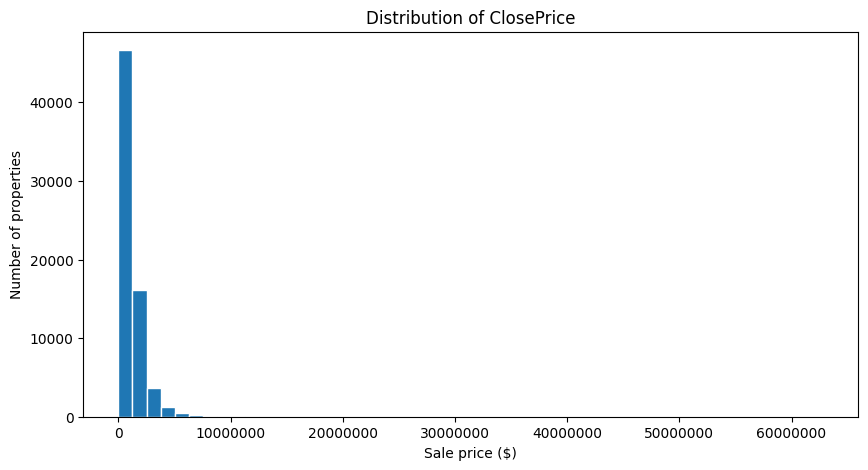

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    residential_df["ClosePrice"].dropna(),
    bins=50,
    edgecolor="white"
)

plt.title("Distribution of ClosePrice")
plt.xlabel("Sale price ($)")
plt.ylabel("Number of properties")
plt.ticklabel_format(style="plain", axis="x")
plt.show()

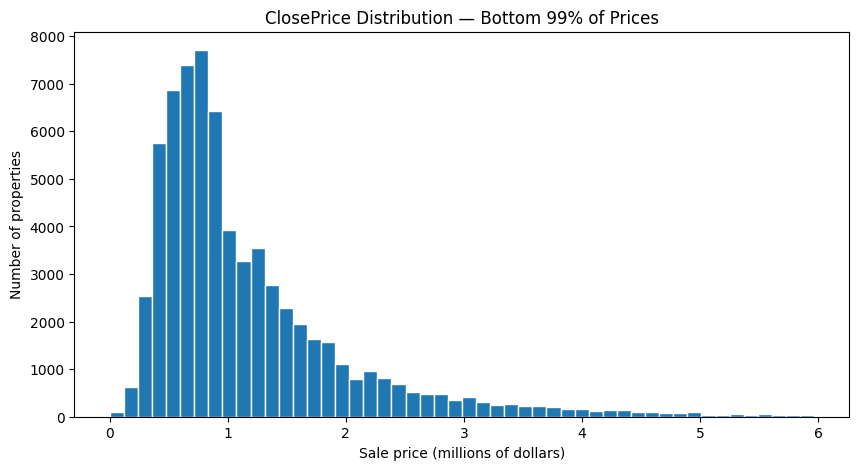

In [13]:
prices = residential_df["ClosePrice"].dropna()
upper_limit = prices.quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(
    prices[prices <= upper_limit] / 1_000_000,
    bins=50,
    edgecolor="white"
)

plt.title("ClosePrice Distribution — Bottom 99% of Prices")
plt.xlabel("Sale price (millions of dollars)")
plt.ylabel("Number of properties")
plt.show()

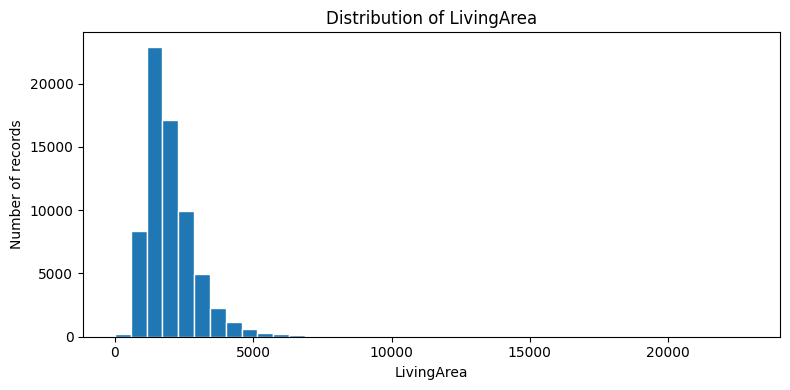

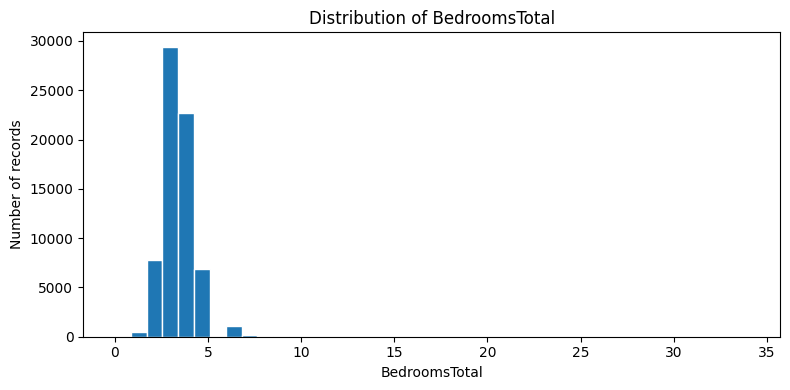

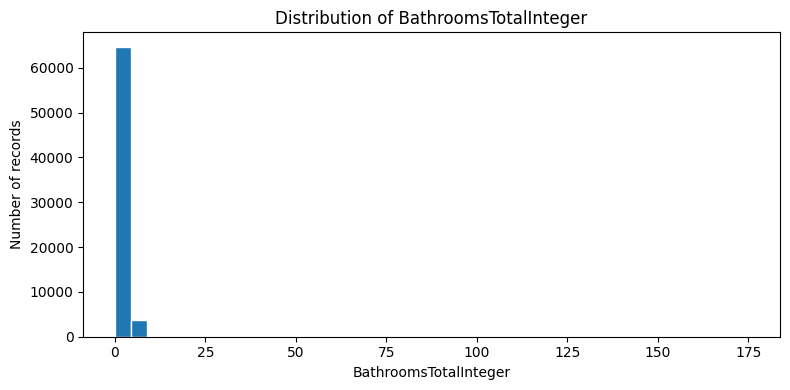

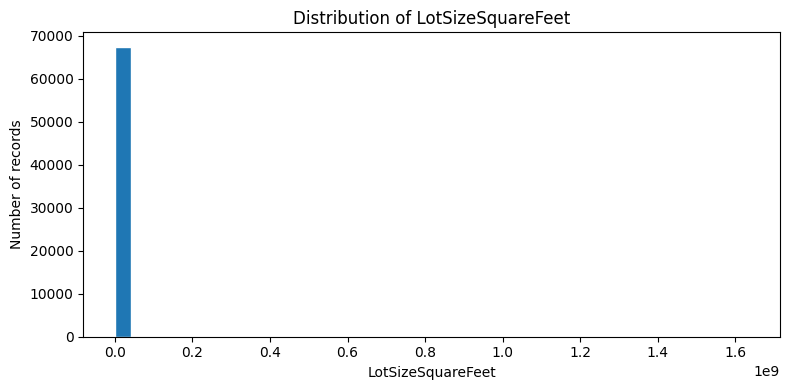

In [14]:
for column in eda_columns[1:]:
    values = residential_df[column].dropna()

    if values.empty:
        print(f"No numeric values available for {column}")
        continue

    plt.figure(figsize=(8, 4))
    plt.hist(values, bins=40, edgecolor="white")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()

In [15]:
lots = pd.to_numeric(
    residential_df["LotSizeSquareFeet"],
    errors="coerce"
)

print(f"Total records: {len(residential_df):,}")
print(f"Missing lot sizes: {lots.isna().sum():,}")

display(
    lots.describe(percentiles=[0.50, 0.95, 0.99])
)

Total records: 68,641
Missing lot sizes: 1,159


,LotSizeSquareFeet
count,6.748200e+04
mean,1.702650e+05
std,1.001770e+07
min,0.000000e+00
50%,7.217000e+03
95%,4.922280e+04
99%,2.443710e+05
max,1.633500e+09


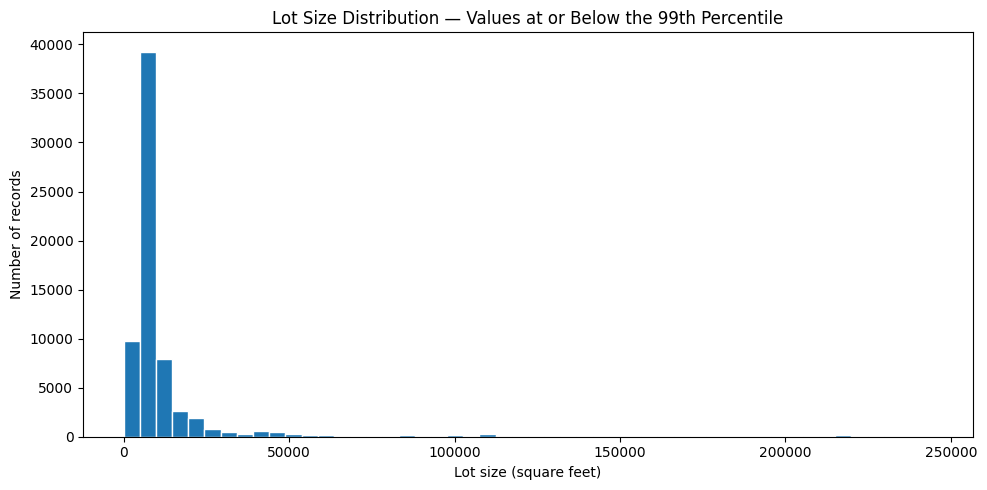

In [16]:
import matplotlib.pyplot as plt

upper_limit = lots.quantile(0.99)
plot_values = lots[lots.between(0, upper_limit)]

plt.figure(figsize=(10, 5))
plt.hist(plot_values, bins=50, edgecolor="white")
plt.title("Lot Size Distribution — Values at or Below the 99th Percentile")
plt.xlabel("Lot size (square feet)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

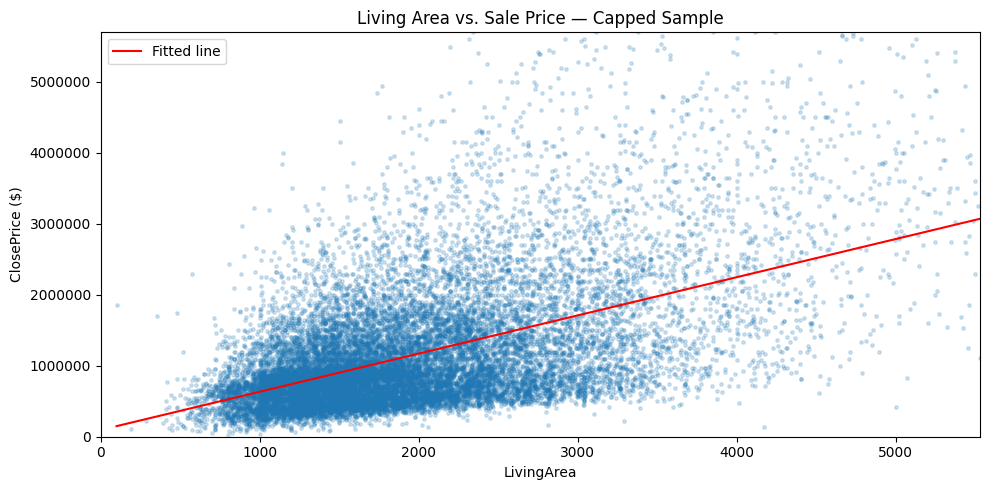

Records plotted: 19,683
Pearson correlation: 0.536


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare numeric values without changing residential_df.
values = residential_df[
    ["LivingArea", "ClosePrice"]
].apply(pd.to_numeric, errors="coerce")

# Use finite, positive values for this comparison.
values = values.replace([np.inf, -np.inf], np.nan).dropna()
values = values.loc[
    values["LivingArea"].gt(0)
    & values["ClosePrice"].gt(0)
]

if len(values) < 2:
    raise ValueError("Not enough valid records for this plot.")

# Select up to 20,000 records reproducibly.
sample = values.sample(
    n=min(20_000, len(values)),
    random_state=0
)

# Limit the plotted sample to its 99th-percentile values.
x_cap = sample["LivingArea"].quantile(0.99)
y_cap = sample["ClosePrice"].quantile(0.99)

plot_data = sample.loc[
    sample["LivingArea"].le(x_cap)
    & sample["ClosePrice"].le(y_cap)
]

x = plot_data["LivingArea"]
y = plot_data["ClosePrice"]

if len(plot_data) < 2 or x.nunique() < 2:
    raise ValueError("Not enough variation to fit a line.")

# Fit a straight line and calculate Pearson correlation.
slope, intercept = np.polyfit(x, y, 1)
correlation = x.corr(y)

plt.figure(figsize=(10, 5))
plt.scatter(x, y, s=6, alpha=0.2)

line_x = np.array([x.min(), x.max()])
plt.plot(
    line_x,
    slope * line_x + intercept,
    color="red",
    label="Fitted line"
)

plt.xlim(0, x_cap)
plt.ylim(0, y_cap)
plt.xlabel("LivingArea")
plt.ylabel("ClosePrice ($)")
plt.title("Living Area vs. Sale Price — Capped Sample")
plt.ticklabel_format(style="plain", axis="both")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Records plotted: {len(plot_data):,}")
print(f"Pearson correlation: {correlation:.3f}")

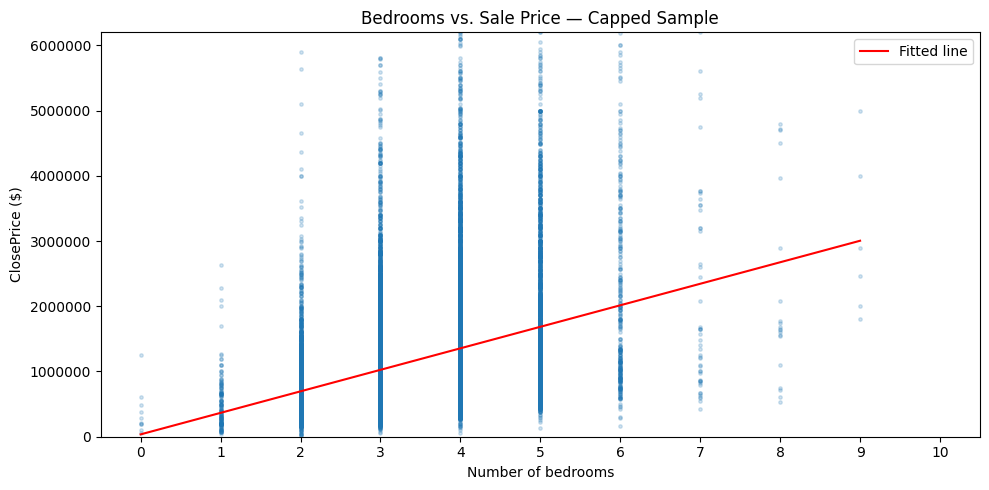

Records plotted: 19,803
Pearson correlation: 0.350


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare numeric values without changing the original data.
values = residential_df[
    ["BedroomsTotal", "ClosePrice"]
].apply(pd.to_numeric, errors="coerce")

values = values.replace([np.inf, -np.inf], np.nan).dropna()

# Plot records with 0–10 bedrooms and positive sale prices.
values = values.loc[
    values["BedroomsTotal"].between(0, 10)
    & values["ClosePrice"].gt(0)
]

if len(values) < 2:
    raise ValueError("Not enough valid records for this plot.")

bedroom_sample = values.sample(
    n=min(20_000, len(values)),
    random_state=0
)

y_cap = bedroom_sample["ClosePrice"].quantile(0.99)

plot_data = bedroom_sample.loc[
    bedroom_sample["ClosePrice"].le(y_cap)
]

x = plot_data["BedroomsTotal"]
y = plot_data["ClosePrice"]

if len(plot_data) < 2 or x.nunique() < 2:
    raise ValueError("Not enough variation to fit a line.")

slope, intercept = np.polyfit(x, y, 1)
correlation = x.corr(y)

plt.figure(figsize=(10, 5))
plt.scatter(x, y, s=6, alpha=0.2)

line_x = np.array([x.min(), x.max()])
plt.plot(
    line_x,
    slope * line_x + intercept,
    color="red",
    label="Fitted line"
)

plt.xlim(-0.5, 10.5)
plt.xticks(range(11))
plt.ylim(0, y_cap)
plt.xlabel("Number of bedrooms")
plt.ylabel("ClosePrice ($)")
plt.title("Bedrooms vs. Sale Price — Capped Sample")
plt.ticklabel_format(style="plain", axis="y")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Records plotted: {len(plot_data):,}")
print(f"Pearson correlation: {correlation:.3f}")

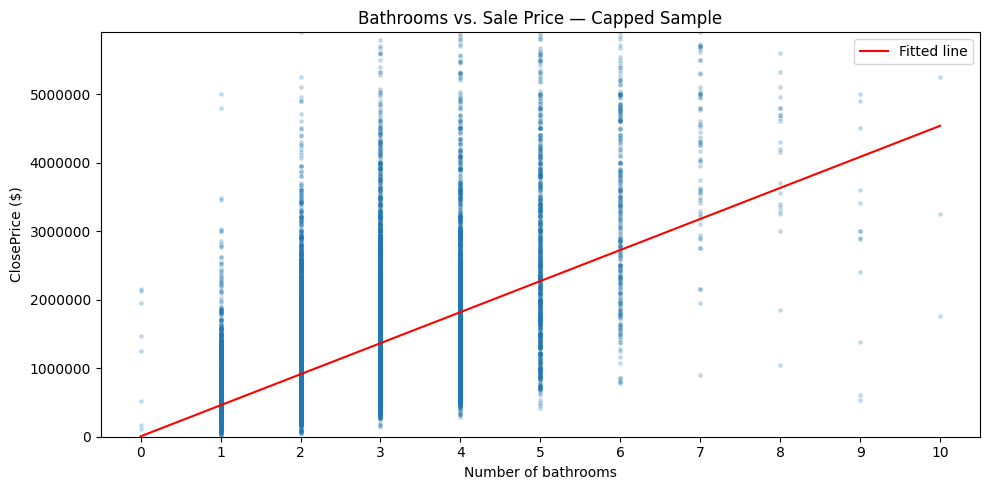

Records plotted: 19,802
Pearson correlation (r): 0.541


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare numeric values without changing residential_df.
values = residential_df[
    ["BathroomsTotalInteger", "ClosePrice"]
].apply(pd.to_numeric, errors="coerce")

values = values.replace([np.inf, -np.inf], np.nan).dropna()

# Plot 0–10 bathrooms and positive sale prices.
values = values.loc[
    values["BathroomsTotalInteger"].between(0, 10)
    & values["ClosePrice"].gt(0)
]

if len(values) < 2:
    raise ValueError("Not enough valid records for this plot.")

bathroom_sample = values.sample(
    n=min(20_000, len(values)),
    random_state=0
)

y_cap = bathroom_sample["ClosePrice"].quantile(0.99)

plot_data = bathroom_sample.loc[
    bathroom_sample["ClosePrice"].le(y_cap)
]

x = plot_data["BathroomsTotalInteger"]
y = plot_data["ClosePrice"]

if len(plot_data) < 2 or x.nunique() < 2:
    raise ValueError("Not enough variation to fit a line.")

slope, intercept = np.polyfit(x, y, 1)
r = x.corr(y)

plt.figure(figsize=(10, 5))
plt.scatter(x, y, s=6, alpha=0.2)

line_x = np.array([x.min(), x.max()])
plt.plot(
    line_x,
    slope * line_x + intercept,
    color="red",
    label="Fitted line"
)

plt.xlim(-0.5, 10.5)
plt.xticks(range(11))
plt.ylim(0, y_cap)
plt.xlabel("Number of bathrooms")
plt.ylabel("ClosePrice ($)")
plt.title("Bathrooms vs. Sale Price — Capped Sample")
plt.ticklabel_format(style="plain", axis="y")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Records plotted: {len(plot_data):,}")
print(f"Pearson correlation (r): {r:.3f}")

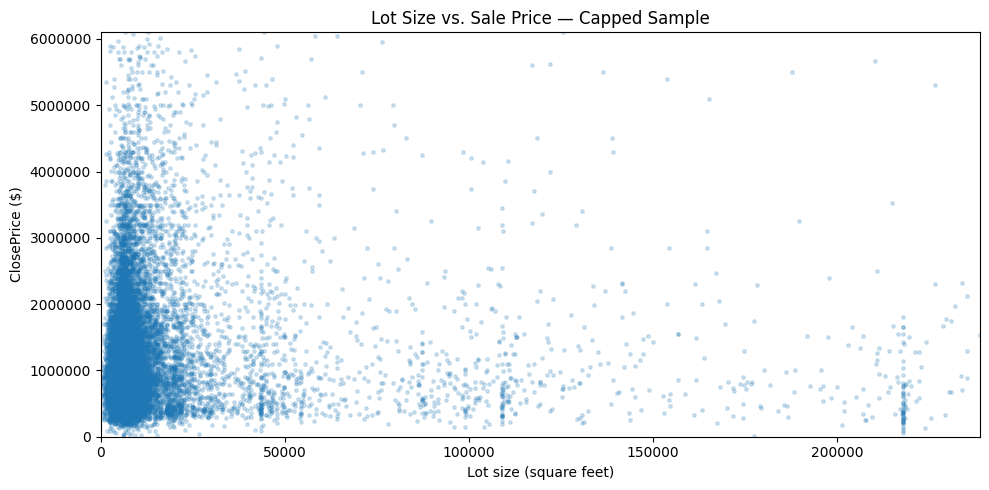

Records plotted: 19,605


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare numeric values without changing residential_df.
values = residential_df[
    ["LotSizeSquareFeet", "ClosePrice"]
].apply(pd.to_numeric, errors="coerce")

values = values.replace([np.inf, -np.inf], np.nan).dropna()

# Use positive lot sizes and sale prices for this plot.
values = values.loc[
    values["LotSizeSquareFeet"].gt(0)
    & values["ClosePrice"].gt(0)
]

if values.empty:
    raise ValueError("No valid records available for this plot.")

lot_sample = values.sample(
    n=min(20_000, len(values)),
    random_state=0
)

x_cap = lot_sample["LotSizeSquareFeet"].quantile(0.99)
y_cap = lot_sample["ClosePrice"].quantile(0.99)

plot_data = lot_sample.loc[
    lot_sample["LotSizeSquareFeet"].le(x_cap)
    & lot_sample["ClosePrice"].le(y_cap)
]

plt.figure(figsize=(10, 5))
plt.scatter(
    plot_data["LotSizeSquareFeet"],
    plot_data["ClosePrice"],
    s=6,
    alpha=0.2
)

plt.xlim(0, x_cap)
plt.ylim(0, y_cap)
plt.xlabel("Lot size (square feet)")
plt.ylabel("ClosePrice ($)")
plt.title("Lot Size vs. Sale Price — Capped Sample")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

print(f"Records plotted: {len(plot_data):,}")

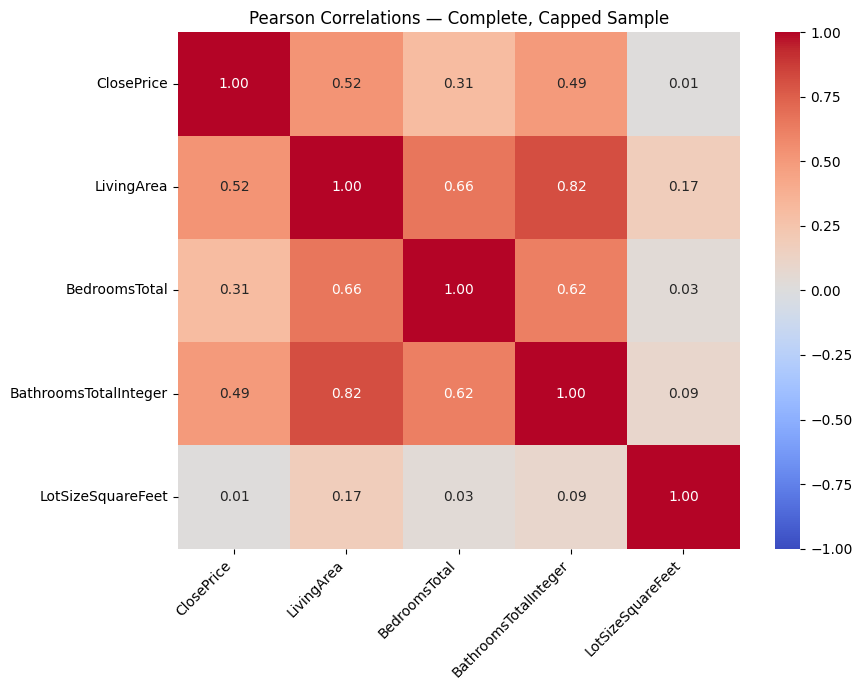

Records used: 19,414


In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

cols = [
    "ClosePrice",
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet"
]

# Prepare numeric values without changing residential_df.
heat = residential_df[cols].apply(
    pd.to_numeric, errors="coerce"
)

heat = heat.replace([np.inf, -np.inf], np.nan).dropna()

# Use positive prices/areas and nonnegative bedroom/bathroom counts.
heat = heat.loc[
    heat["ClosePrice"].gt(0)
    & heat["LivingArea"].gt(0)
    & heat["LotSizeSquareFeet"].gt(0)
    & heat["BedroomsTotal"].ge(0)
    & heat["BathroomsTotalInteger"].ge(0)
]

if len(heat) < 2:
    raise ValueError("Not enough complete records for correlations.")

heat = heat.sample(
    n=min(20_000, len(heat)),
    random_state=0
)

# Keep rows at or below each field's sample 99th percentile.
caps = heat.quantile(0.99)
heat = heat.loc[heat.le(caps).all(axis=1)]

if len(heat) < 2:
    raise ValueError("Not enough records remain after percentile filtering.")

correlation = heat.corr(method="pearson")

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Pearson Correlations — Complete, Capped Sample")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"Records used: {len(heat):,}")